# TfL bus analysis: exploratory data analysis

Phase 2. A first look at every dataset before choosing the analyses:

1. **Daily journeys** (Tube and bus, 2019 to Nov 2026): recovery after COVID, weekdays vs weekends, disruption days.
2. **Daily station footfall**: coverage, and what the Elizabeth line openings look like day by day.
3. **BUSTO bus demand** (2023-24 to 2025-26): totals, time of day, what the crowding measure means, stability between years.
4. **Bus demand near rail**: how much bus travel starts near a TfL rail station, by time of day.

"Rail" means TfL rail only (Underground, Overground, DLR, Elizabeth line), as in the rest of the project.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

import tfl_bus as B

B.RESULTS.mkdir(parents=True, exist_ok=True)
con = B.busto_con()
q = lambda sql: con.execute(sql).df()

## 1. Daily Tube and bus journeys

01 Jan 2019 to 14 Nov 2026: 2,875 days, 0 missing


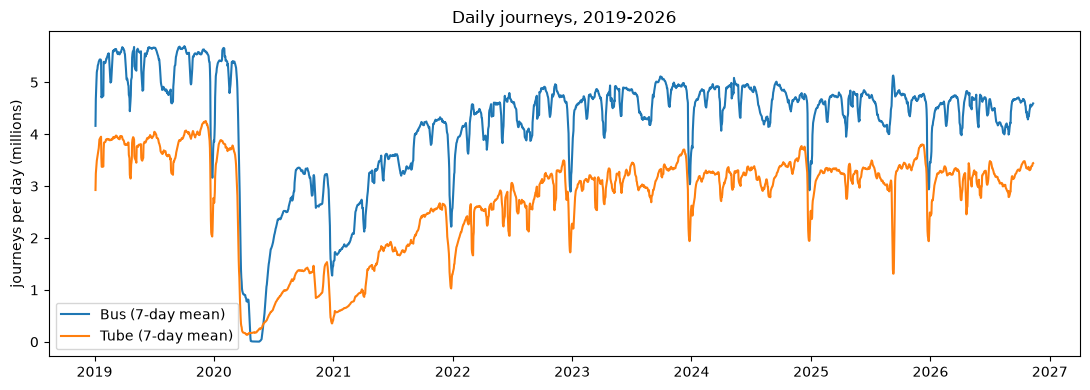

In [2]:
j = B.load_journeys()
j['weekend'] = j.index.dayofweek >= 5
print(f"{j.index.min():%d %b %Y} to {j.index.max():%d %b %Y}: {len(j):,} days, "
      f"{len(pd.date_range(j.index.min(), j.index.max()).difference(j.index))} missing")

fig, ax = plt.subplots(figsize=(11, 4))
for mode in ['bus', 'tube']:
    ax.plot(j.index, j[mode].rolling(7, center=True).mean() / 1e6, label=f'{mode.capitalize()} (7-day mean)')
ax.set_ylabel('journeys per day (millions)'); ax.legend(); ax.set_title('Daily journeys, 2019-2026')
ax.xaxis.set_major_locator(mdates.YearLocator()); plt.tight_layout(); plt.show()

**Recovery against 2019.** Each day is compared with the 2019 mean for the same month and day type
(weekday / weekend), which removes the seasonal pattern. Christmas Day (no Tube service) is excluded.

In [3]:
jj = j[~((j.index.month == 12) & (j.index.day == 25))].copy()
jj['month'], jj['year'] = jj.index.month, jj.index.year
base = jj[jj.year == 2019].groupby(['month', 'weekend'])[['tube', 'bus']].mean()
rel = jj[['tube', 'bus']] / base.reindex(pd.MultiIndex.from_arrays([jj.month, jj.weekend])).values

annual = (100 * rel.groupby([jj.year, jj.weekend.map({False: 'weekday', True: 'weekend'})]).mean()).unstack().round(1)
annual.columns = [f'{m} {d}' for m, d in annual.columns]
annual.to_csv(B.RESULTS / 'recovery_vs_2019.csv')
annual

,tube weekday,tube weekend,bus weekday,bus weekend
year,,,,
2019,100.0,100.0,100.0,100.0
2020,37.0,36.8,51.2,50.7
2021,41.6,49.2,60.1,62.0
2022,66.3,83.1,80.4,86.5
2023,79.0,95.6,86.3,93.7
2024,81.2,97.7,86.1,94.8
2025,81.5,98.1,83.8,92.2
2026,80.4,97.0,81.8,92.2


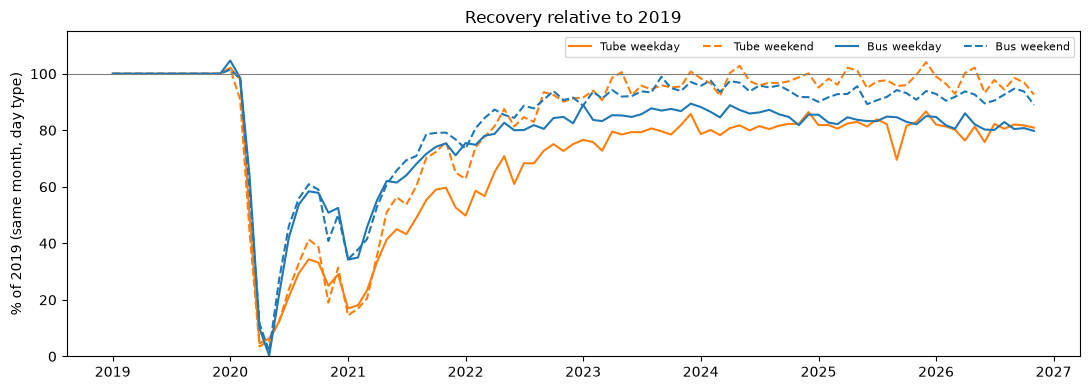

      weekend
tube  False      80.5
      True       97.0
bus   False      84.5
      True       93.2
Name: mean since 2023 (%), dtype: float64


In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
monthly = 100 * rel.groupby([jj.index.to_period('M'), jj.weekend]).mean().unstack()
for (mode, wk), style in zip([('tube', False), ('tube', True), ('bus', False), ('bus', True)],
                             ['C1-', 'C1--', 'C0-', 'C0--']):
    s = monthly[(mode, wk)]
    ax.plot(s.index.to_timestamp(), s, style, label=f"{mode.capitalize()} {'weekend' if wk else 'weekday'}")
ax.axhline(100, color='grey', lw=.8); ax.set_ylim(0, 115)
ax.set_ylabel('% of 2019 (same month, day type)'); ax.legend(ncol=4, fontsize=8)
ax.set_title('Recovery relative to 2019'); plt.tight_layout(); plt.show()
print((monthly.loc['2023-01':].mean()).round(1).rename('mean since 2023 (%)'))

**Atypical days.** Each day is compared with the median of the surrounding four weeks
(same weekday/weekend type). Days far below it are classified as:

* **Tube strike**: Tube under 50% of normal while buses run at least 90% of normal;
* **bus strike**: the reverse;
* **holiday / other**: both modes well below normal (bank holidays, the Queen's funeral, snow, ...).

The list of atypical days is reused to clean the daily station series below.

In [5]:
# normal level: rolling 29-day median of the same day type (weekday / weekend)
norm = pd.concat([j[j.weekend == w][['tube', 'bus']].rolling(29, center=True, min_periods=8).median()
                  for w in (False, True)]).sort_index()
ratio = j[['tube', 'bus']] / norm
christmas = (j.index.month == 12) & (j.index.day >= 24) | (j.index.month == 1) & (j.index.day == 1)
kind = pd.Series(None, index=j.index, dtype=object)
kind[(ratio.tube < .5) & (ratio.bus >= .9)] = 'Tube strike'
kind[kind.isna() & (ratio.tube < .75) & (ratio.bus >= .9)] = 'Tube partly disrupted'
kind[(ratio.bus < .5) & (ratio.tube >= .9)] = 'bus strike'
kind[kind.isna() & (ratio.bus < .75) & (ratio.tube >= .9)] = 'buses partly disrupted'
kind[kind.isna() & ((ratio.tube < .75) | (ratio.bus < .75))] = 'holiday / other'
kind[christmas] = 'Christmas / New Year'
atypical = kind.dropna()

out = j.loc[atypical.index, ['dayofweek', 'tube', 'bus']].assign(
    kind=atypical, tube_vs_normal=(100 * ratio.tube).round(0), bus_vs_normal=(100 * ratio.bus).round(0))
out.to_csv(B.RESULTS / 'atypical_days.csv', index_label='date')
print(pd.crosstab(out.index.year, out.kind), '\n')
for k in ['Tube strike', 'Tube partly disrupted']:
    s = out[out.kind == k]
    print(f"{k}: {len(s)} days; bus journeys {s.bus_vs_normal.mean() - 100:+.0f}% vs normal "
          f"(range {s.bus_vs_normal.min() - 100:+.0f}% to {s.bus_vs_normal.max() - 100:+.0f}%)")
out[out.kind.isin(['Tube strike', 'bus strike'])]

kind   Christmas / New Year  Tube partly disrupted  Tube strike  bus strike  \
row_0                                                                         
2019                      9                      0            0           0   
2020                      9                      4            0           4   
2021                      9                      1            0           0   
2022                      9                      2            6           0   
2023                      9                      1            1           0   
2024                      9                      1            0           0   
2025                      9                      3            4           0   
2026                      1                      9            0           0   

kind   buses partly disrupted  holiday / other  
row_0                                           
2019                        0                7  
2020                       10               22  
2021         

,dayofweek,tube,bus,kind,tube_vs_normal,bus_vs_normal
date,,,,,,
2020-05-02,Saturday,118000,5000,bus strike,95.0,1.0
2020-05-09,Saturday,121000,4000,bus strike,98.0,1.0
2020-05-16,Saturday,151000,3000,bus strike,122.0,1.0
2020-05-23,Saturday,177000,37000,bus strike,117.0,7.0
2022-03-01,Tuesday,180000,5310000,Tube strike,7.0,112.0
2022-03-03,Thursday,187000,5321000,Tube strike,7.0,112.0
2022-06-06,Monday,643000,5319000,Tube strike,22.0,105.0
2022-06-21,Tuesday,160000,5537000,Tube strike,5.0,110.0
2022-08-19,Friday,272000,4616000,Tube strike,9.0,107.0


## 2. Daily station footfall

In [6]:
f = B.load_footfall()
yr = f.groupby(f.date.dt.year).agg(stations=('station', 'nunique'), days=('date', 'nunique'))
print(yr.T)
span = f.groupby('station').date.agg(['min', 'max'])
span[(span['min'] > '2019-02-01') | (span['max'] < f.date.max() - pd.Timedelta(days=30))].sort_values('min')

date      2019  2020  2021  2022  2023  2024  2025  2026
stations   421   428   433   435   434   434   434   434
days       365   366   365   365   365   366   365   318


,min,max
station,,
Cannon Street,2019-01-01,2022-12-31
Slough,2019-10-30,2026-11-14
Reading,2019-10-30,2026-11-14
Unknown,2020-02-18,2022-12-31
Langley Berks,2020-10-25,2026-11-14
Twyford,2020-10-25,2026-11-14
Burnham Bucks,2020-10-25,2026-11-14
Taplow,2020-10-25,2026-11-14
Iver,2020-10-25,2026-11-14


Footfall counts **entry and exit taps** per station, including Elizabeth line passengers at shared
gates. Some Elizabeth line stations have their own series (`Paddington EL`, `Canary Wharf EL`, ...);
station names gain or lose series as lines open (Battersea Power Station, Nine Elms, Barking Riverside)
and `Unknown` / `Cannon Street` change between 2022 and 2023.

### The Elizabeth line openings, day by day

Weekday footfall (5-weekday rolling mean, atypical days removed) at the four central stations used in the annual
analysis, with two nearby stations without the line for comparison. Dates: central section opened
**24 May 2022**, Bond Street **24 Oct 2022**, through services from the east and west **6 Nov 2022**.

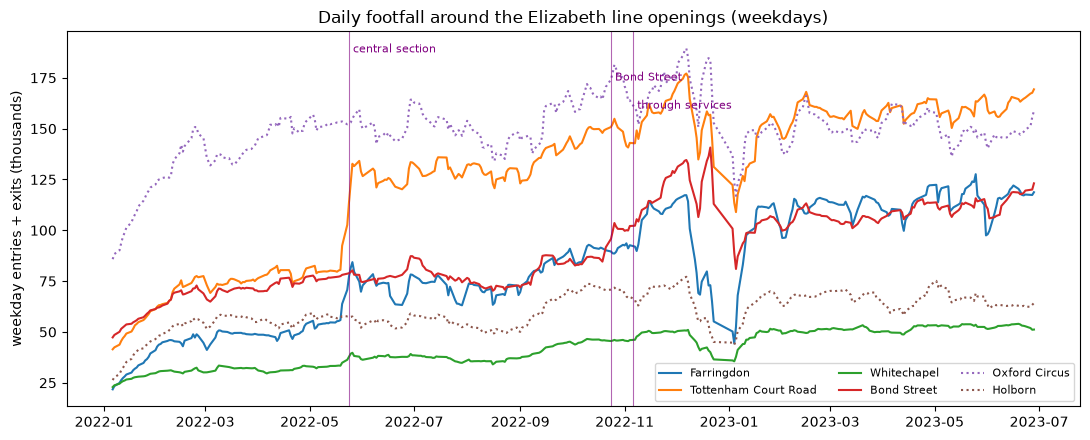

In [7]:
# weekdays only, without bank holidays, strikes and other atypical days found above
wk = f[(f.date.dt.dayofweek < 5) & ~f.date.isin(atypical.index)].pivot_table(index='date', columns='station', values='entries_exits')
treated = ['Farringdon', 'Tottenham Court Road', 'Whitechapel', 'Bond Street']
nearby = ['Oxford Circus', 'Holborn']
events = {'central section': '2022-05-24', 'Bond Street': '2022-10-24', 'through services': '2022-11-06'}

fig, ax = plt.subplots(figsize=(11, 4.5))
for s in treated + nearby:
    ax.plot(wk.loc['2022-01-01':'2023-06-30', s].rolling(5, center=True).mean() / 1e3,
            ls='-' if s in treated else ':', label=s)
for k, (name, d) in enumerate(events.items()):
    ax.axvline(pd.Timestamp(d), color='purple', lw=.8, alpha=.6)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * (.97 - .07 * k), ' ' + name, fontsize=8, color='purple', va='top')
ax.set_ylabel('weekday entries + exits (thousands)'); ax.legend(fontsize=8, ncol=3)
ax.set_title('Daily footfall around the Elizabeth line openings (weekdays)'); plt.tight_layout(); plt.show()

In [8]:
# Four weeks before vs four weeks after each opening (weekdays), relative to the nearby stations
def before_after(stations, date, weeks=4):
    d = pd.Timestamp(date)
    pre = wk.loc[d - pd.Timedelta(weeks=weeks):d - pd.Timedelta(days=1)].mean()
    post = wk.loc[d:d + pd.Timedelta(weeks=weeks)].mean()
    chg = 100 * (post / pre - 1)
    return chg[stations].round(1), chg[nearby].mean().round(1)

rows = []
for s, d in [*[(s, events['central section']) for s in ['Farringdon', 'Tottenham Court Road', 'Whitechapel']],
             ('Bond Street', events['Bond Street'])]:
    c, ctrl = before_after([s], d)
    rows.append({'station': s, 'opening': d, 'change (%)': c[s], 'nearby stations (%)': ctrl,
                 'difference (pp)': round(c[s] - ctrl, 1)})
pd.DataFrame(rows)

,station,opening,change (%),nearby stations (%),difference (pp)
0,Farringdon,2022-05-24,42.5,-2.3,44.8
1,Tottenham Court Road,2022-05-24,60.1,-2.3,62.4
2,Whitechapel,2022-05-24,16.1,-2.3,18.4
3,Bond Street,2022-10-24,24.3,-0.9,25.2


The step at opening is visible in the daily data for Tottenham Court Road and Bond Street; Farringdon
and Whitechapel grow more gradually (both were already interchanges). This is enough to re-estimate the
effect from daily data in a later phase, with proper controls and the school-holiday calendar.

## 3. BUSTO bus demand

BUSTO gives, for a **typical day** of each type in a financial year, the average boardings,
alightings, on-board load and capacity for every route, direction, stop and quarter hour.
Summing boardings over a day type gives average daily boardings.

In [9]:
tot = q('''SELECT year, day_type, sum(boardings) AS boardings FROM qhr GROUP BY ALL''')
tot = tot.pivot(index='year', columns='day_type', values='boardings')[B.DAY_TYPES] / 1e6
tot.index = tot.index.map(B.BUSTO_YEARS)

# Network Demand bus journeys over the same financial years (April-March)
jfy = j.assign(fy=j.index.year - (j.index.month < 4))
nd = pd.DataFrame({
    'Weekday': jfy[jfy.index.dayofweek < 5].groupby('fy').bus.mean(),
    'Saturday': jfy[jfy.index.dayofweek == 5].groupby('fy').bus.mean(),
    'Sunday': jfy[jfy.index.dayofweek == 6].groupby('fy').bus.mean(),
}).loc[list(B.BUSTO_YEARS)] / 1e6
nd.index = nd.index.map(B.BUSTO_YEARS)
compare = pd.concat({'BUSTO boardings (M/day)': tot, 'journeys (M/day)': nd,
                     'boardings per journey': tot / nd}, axis=1).round(2)
compare

BUSTO boardings (M/day)                 journeys (M/day)           \
day_type                  Weekday Saturday Sunday          Weekday Saturday   
2023-2024                    5.71     4.70   3.42             5.04     4.34   
2024-2025                    5.38     4.49   3.32             4.96     4.27   
2025-2026                    5.32     4.43   3.34             4.86     4.19   

                 boardings per journey                  
day_type  Sunday               Weekday Saturday Sunday  
2023-2024   3.25                  1.13     1.08   1.05  
2024-2025   3.25                  1.09     1.05   1.02  
2025-2026   3.20                  1.10     1.06   1.04

BUSTO counts **boardings**, Network Demand counts **journeys**; the ratio (about 1.1) reflects
passengers changing buses, e.g. within the one-hour Hopper fare. BUSTO falls faster between 2023-24
and 2025-26 (weekday -7%) than journeys (-4%), so year-to-year changes in BUSTO should be read
with care.

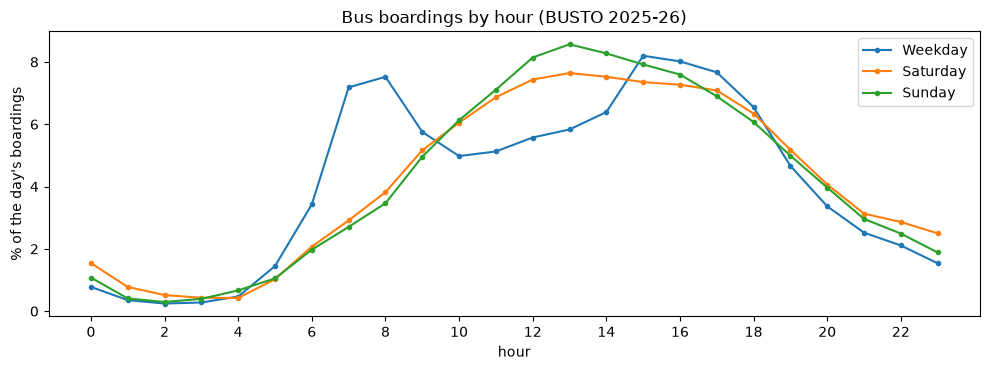

In [10]:
prof = q('''SELECT year, day_type, hour(qhr) AS hour, sum(boardings) AS b FROM qhr GROUP BY ALL''')
prof['share'] = 100 * prof.b / prof.groupby(['year', 'day_type']).b.transform('sum')
fig, ax = plt.subplots(figsize=(10, 3.8))
for dt in B.DAY_TYPES:
    p = prof.query('year == 2025 and day_type == @dt').sort_values('hour')
    ax.plot(p.hour, p.share, marker='.', label=dt)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hour'); ax.set_ylabel('% of the day\'s boardings')
ax.set_title('Bus boardings by hour (BUSTO 2025-26)'); ax.legend(); plt.tight_layout(); plt.show()

### What does the crowding measure mean?

`v_c` is exactly `load / capacity`. Both are **per quarter hour**: load is passengers on board passing
the stop, capacity is the total passenger space (seats + standing) of the buses passing in those 15
minutes. At quiet times a quarter hour may contain only part of one scheduled bus, so a few passengers
give a ratio above 1. Those rows are artefacts of low capacity, not crowding.

In [11]:
vc = q('''
    SELECT CASE WHEN capacity < 20 THEN '< 20' WHEN capacity < 60 THEN '20-60'
                WHEN capacity < 150 THEN '60-150' ELSE '150+' END AS capacity_per_qhr,
           count(*) AS rows, round(100 * avg((v_c > 1)::int), 3) AS pct_over_capacity,
           round(100 * avg((load > seats)::int), 2) AS pct_standing, round(quantile_cont(v_c, .99), 2) AS p99_v_c
    FROM qhr WHERE year = 2025 AND day_type = 'Weekday' GROUP BY 1 ORDER BY min(capacity)''')
vc

,capacity_per_qhr,rows,pct_over_capacity,pct_standing,p99_v_c
0,< 20,223447,0.059,0.80,0.53
1,20-60,817150,0.000,1.28,0.54
2,60-150,2167358,0.000,0.39,0.55
3,150+,299491,0.000,0.21,0.60


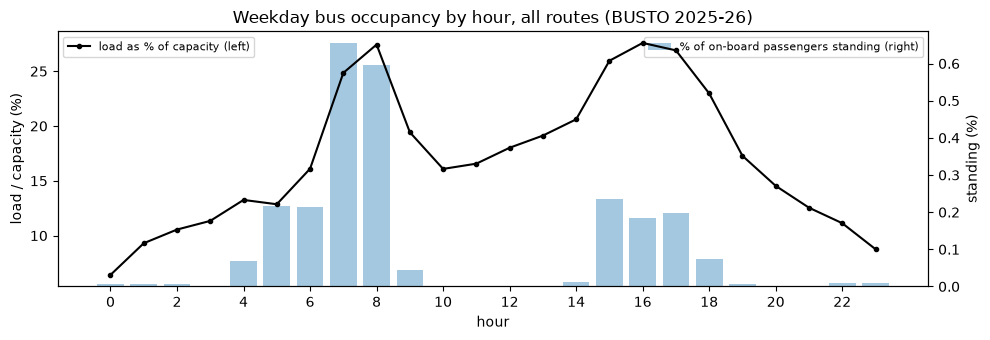

In [12]:
std = q('''
    SELECT hour(qhr) AS hour, sum(greatest(load - seats, 0)) / sum(load) AS standing_share,
           sum(load) / sum(capacity) AS mean_vc
    FROM qhr WHERE year = 2025 AND day_type = 'Weekday' GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(std.hour, 100 * std.mean_vc, 'k.-', label='load as % of capacity (left)')
ax2 = ax.twinx()
ax2.bar(std.hour, 100 * std.standing_share, alpha=.4, label='% of on-board passengers standing (right)')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hour'); ax.set_ylabel('load / capacity (%)')
ax2.set_ylabel('standing (%)'); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.legend(loc='upper left', fontsize=8); ax2.legend(loc='upper right', fontsize=8)
ax.set_title('Weekday bus occupancy by hour, all routes (BUSTO 2025-26)'); plt.tight_layout(); plt.show()

Averaged over a typical day, buses are rarely full: load exceeds seats in under 1% of weekday
quarter-hour rows. Crowding will therefore need to be studied where and when it concentrates, e.g.
the busiest route sections in the peak hours, rather than from network averages. The separate
"max demand hour by route by timeband" files give each route's busiest hour and should help.

In [13]:
mx = q('''SELECT * FROM maxhr WHERE year = 2025 LIMIT 5''')
print(q('SELECT year, day_type, count(*) AS rows, count(DISTINCT route) AS routes FROM maxhr GROUP BY ALL ORDER BY 1, 2'))
mx

   year  day_type    rows  routes
0  2023  Saturday  237544     601
1  2023    Sunday  236682     578
2  2023   Weekday  317760     602
3  2024  Saturday  233197     603
4  2024    Sunday  229527     583
5  2024   Weekday  327653     604
6  2025  Saturday  235538     605
7  2025    Sunday  232423     586
8  2025   Weekday  330461     606


,year,day_type,timeband,qhr,route,direction,stopcode,stopname,stopsequence,hourboardings,houralightings,hourload,hourcapacity,hourseats,v_c
0,2025,Weekday,1.0,06:45:00,1,1,29927,ROYAL FREE HOSPITAL,1.0,13.98242,0.00000,13.98242,578.31524,398.83810,0.02418
1,2025,Weekday,1.0,06:45:00,1,1,12053,ROSSLYN HILL,2.0,0.91524,0.07374,14.84780,574.83524,396.43810,0.02583
2,2025,Weekday,1.0,06:45:00,1,1,12058,HAVERSTOCK HILL / POND STREET,3.0,6.24587,0.32431,20.59824,577.25190,398.10476,0.03568
3,2025,Weekday,1.0,06:45:00,1,1,12060,BELSIZE PARK STATION,4.0,6.14074,1.59784,24.97258,577.01024,397.93810,0.04328
4,2025,Weekday,1.0,06:45:00,1,1,BP2006,DOWNSIDE CRESCENT,5.0,2.98471,1.33910,26.59077,574.83524,396.43810,0.04626


In [14]:
peak = q('''
    SELECT route, direction, stopname, qhr AS hour_start, timeband,
           round(hourload, 0) AS load, round(hourcapacity, 0) AS capacity, round(hourseats, 0) AS seats, round(v_c, 2) AS v_c
    FROM maxhr WHERE year = 2025 AND day_type = 'Weekday' AND hourcapacity >= 200
    ORDER BY v_c DESC LIMIT 12''')
print('Highest load/capacity in the busiest hour, weekday 2025-26 (capacity >= 200 per hour):')
peak

Highest load/capacity in the busiest hour, weekday 2025-26 (capacity >= 200 per hour):


,route,direction,stopname,hour_start,timeband,load,capacity,seats,v_c
0,SL9,1,YEADING / WHITE HART ROUNDABOUT,07:00:00,2.0,338.0,377.0,260.0,0.90
1,SL9,1,NORTHOLT PARK STATION,07:15:00,2.0,323.0,365.0,252.0,0.89
2,281,2,TAYBEN AVENUE,16:30:00,4.0,408.0,461.0,318.0,0.89
3,281,2,KNELLER HALL,16:30:00,4.0,413.0,469.0,323.0,0.88
4,281,2,WARREN ROAD,16:30:00,4.0,404.0,466.0,321.0,0.87
5,35,1,ELEPHANT & CASTLE / NEWINGTON CAUSEWAY,06:45:00,1.0,334.0,389.0,268.0,0.86
6,35,1,BOROUGH STATION,06:45:00,1.0,333.0,389.0,269.0,0.86
7,35,2,MONUMENT STATION,17:15:00,4.0,488.0,568.0,392.0,0.86
8,SL9,1,NORTHOLT STATION,07:15:00,2.0,325.0,381.0,263.0,0.85
9,35,1,INNER LONDON CROWN COURT,06:45:00,1.0,335.0,392.0,271.0,0.85


In [15]:
routes = q('''SELECT year, route, sum(boardings) AS b FROM qhr WHERE day_type = 'Weekday' GROUP BY ALL''') \
    .pivot(index='route', columns='year', values='b')
print('Spearman correlation of route weekday boardings between years:')
print(routes.corr(method='spearman').round(3))
both = routes.dropna()
chg = 100 * (both[2025] / both[2023] - 1)
print(f"\nroutes in both 2023-24 and 2025-26: {len(both)}; median change {chg.median():.1f}%, "
      f"IQR {chg.quantile(.25):.1f}% to {chg.quantile(.75):.1f}%")
top = (routes[2025].nlargest(10) / 1e3).round(1).rename('weekday boardings 2025-26 (000s)').to_frame()
top['change since 2023-24 (%)'] = chg.reindex(top.index).round(1)
top

Spearman correlation of route weekday boardings between years:
year   2023   2024   2025
year                     
2023  1.000  0.992  0.988
2024  0.992  1.000  0.993
2025  0.988  0.993  1.000

routes in both 2023-24 and 2025-26: 593; median change -7.5%, IQR -12.6% to -1.9%


,weekday boardings 2025-26 (000s),change since 2023-24 (%)
route,,
18,36.4,-2.8
149,34.2,-6.6
29,32.2,-4.7
5,30.7,5.4
86,28.6,-8.9
25,28.6,-11.8
207,28.2,-9.9
35,27.9,-6.0
243,27.5,-3.9


## 4. Bus demand near TfL rail, by time of day

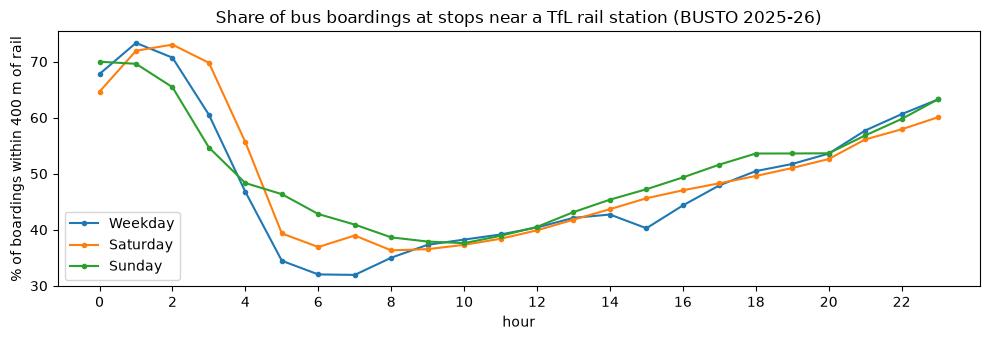

In [16]:
linked = pd.read_parquet(B.PROCESSED / 'bus-stops-linked.parquet')
con.register('linked', linked.reset_index()[['stopcode', 'dist_m']])
near = q(f'''
    SELECT q.day_type, hour(q.qhr) AS hour,
           sum(CASE WHEN l.dist_m <= {B.WALK_M} THEN q.boardings ELSE 0 END) / sum(q.boardings) AS share_near
    FROM qhr q JOIN linked l USING (stopcode) WHERE q.year = 2025 GROUP BY ALL''')
fig, ax = plt.subplots(figsize=(10, 3.5))
for dt in B.DAY_TYPES:
    p = near.query('day_type == @dt').sort_values('hour')
    ax.plot(p.hour, 100 * p.share_near, marker='.', label=dt)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hour')
ax.set_ylabel(f'% of boardings within {B.WALK_M} m of rail')
ax.set_title('Share of bus boardings at stops near a TfL rail station (BUSTO 2025-26)')
ax.legend(); plt.tight_layout(); plt.show()

## 5. Where did bus boardings fall between 2023-24 and 2025-26?

BUSTO starts after the Elizabeth line opened, so a before/after comparison for buses is not possible.
What BUSTO can show is how bus demand changed **since** 2023-24, and whether that differs near the line.
Weekday boardings per stop, stops present in both years.

In [17]:
per_stop = q('''SELECT year, stopcode, sum(boardings) AS b FROM qhr WHERE day_type = 'Weekday' GROUP BY ALL''') \
    .pivot(index='stopcode', columns='year', values='b')
d = per_stop.join(linked[['dist_m', 'lat', 'lon']], how='inner').dropna(subset=[2023, 2025])
rail = B.rail_stations()
el_stations = rail.index[rail['lines'].str.contains('Elizabeth')]
links400 = B.bus_rail_links(linked, rail, B.WALK_M)
d['near_elizabeth_line'] = d.index.isin(links400.loc[links400.station.isin(el_stations), 'stopcode'])
d['distance_to_rail'] = pd.cut(d.dist_m, [0, 400, 800, 2000, np.inf], right=False,
                               labels=['< 400 m', '400-800 m', '800 m - 2 km', '> 2 km'])
d['from_centre'] = pd.cut(B.haversine_m(d.lat, d.lon, 51.5080, -0.1246) / 1000, [0, 3, 6, 10, 15, 40],
                          labels=['0-3 km', '3-6 km', '6-10 km', '10-15 km', '15+ km'])

def change(by):
    g = d.groupby(by, observed=True)[[2023, 2025]].sum()
    return pd.DataFrame({'stops': d.groupby(by, observed=True).size(),
                         'weekday boardings 2023-24': g[2023].round(-3).astype(int),
                         'change to 2025-26 (%)': (100 * (g[2025] / g[2023] - 1)).round(1)})

print(f"all stops: {100 * (d[2025].sum() / d[2023].sum() - 1):.1f}%")
display(change('near_elizabeth_line'), change('distance_to_rail'), change('from_centre'))

all stops: -6.9%


,stops,weekday boardings 2023-24,change to 2025-26 (%)
near_elizabeth_line,,,
False,18217,5317000,-7.2
True,364,338000,-1.4


,stops,weekday boardings 2023-24,change to 2025-26 (%)
distance_to_rail,,,
< 400 m,3954,2441000,-6.9
400-800 m,3877,1114000,-8.5
800 m - 2 km,5363,1292000,-6.8
> 2 km,5387,809000,-4.5


,stops,weekday boardings 2023-24,change to 2025-26 (%)
from_centre,,,
0-3 km,711,525000,-8.6
3-6 km,1797,872000,-11.4
6-10 km,3264,1239000,-7.8
10-15 km,4910,1507000,-4.4
15+ km,7899,1513000,-5.3


In [18]:
el_station_change = []
for s in el_stations:
    stops_ = links400.loc[links400.station == s, 'stopcode']
    x = d.loc[d.index.intersection(stops_), [2023, 2025]].sum()
    if x[2023] > 0:
        el_station_change.append({'station': s, 'bus stops': len(d.index.intersection(stops_)),
                                  'weekday boardings 2023-24': int(round(x[2023], -2)),
                                  'change (%)': round(100 * (x[2025] / x[2023] - 1), 1)})
el_tab = pd.DataFrame(el_station_change).sort_values('weekday boardings 2023-24', ascending=False)
el_tab.to_csv(B.RESULTS / 'bus_change_near_elizabeth_line.csv', index=False)
el_tab.head(15)

,station,bus stops,weekday boardings 2023-24,change (%)
31,Woolwich,14,41700,-11.3
17,Ilford,16,30800,3.5
22,Romford,19,27700,-5.3
26,Stratford,13,27300,18.4
27,Tottenham Court Road,16,24100,-6.0
6,Ealing Broadway,17,22500,11.3
18,Liverpool Street,15,20600,-2.6
2,Bond Street,7,17100,-14.8
13,Hayes & Harlington,10,14000,-4.3
0,Abbey Wood,16,9100,12.1


Bus boardings near Elizabeth line stations held up (about -1%) while the rest of the network fell
about 7%, with the largest falls 3-6 km from the centre. Station by station the changes are noisy and
partly reflect route changes (for example new Superloop routes), so this needs route-level controls
before it can be called an effect.

## 6. Summary of the EDA

**Recovery after COVID (daily journeys).**
* The Tube has settled at about **81% of 2019 on weekdays and 97% at weekends** since 2023.
* Buses recovered faster at first but are now **slipping**: weekdays 86% of 2019 in 2023-24, 82% in 2026;
  weekends about 92%.
* On the 11 full **Tube strike** days since 2022, bus journeys rose only **+5% to +15%**: buses absorb a small
  part of the Tube's passengers.
* May 2020 Saturdays show almost no bus journeys: fares were suspended (rear-door boarding), so few
  passengers tapped. Not a strike.

**Elizabeth line, daily station data.**
* The openings are clear steps in the daily footfall. Four weeks after vs before, relative to Oxford
  Circus and Holborn: Tottenham Court Road +62 points, Farringdon +45, Bond Street +25, Whitechapel +18.
* Daily data with atypical days removed is good enough for an event study around the opening dates.

**BUSTO.**
* About **1.1 boardings per journey**. BUSTO fell faster than journey counts between 2023-24 and 2025-26
  (weekday -7% vs -4%).
* Route rankings are very stable between years (Spearman 0.99); the median route lost 7.5%.
* `v_c` above 1 is an artefact of low per-quarter-hour capacity. Averaged over a typical day, buses
  are rarely full; **standing is concentrated in the morning peak** (07-09), less in the afternoon peak
  even though average occupancy is the same. Crowding analysis should use the busiest-hour file and
  route sections, with a minimum capacity.
* Only **32% of weekday 07:00 boardings** are within 400 m of TfL rail, against about 70% overnight and 40%
  at 15:00 (school travel). Buses mostly serve trips that rail does not.
* Since 2023-24, bus boardings near Elizabeth line stations held up while the rest fell (section 5).